In [1]:
#@title Imports and hyperparameters
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import os
import scipy
from scipy.stats import ttest_rel
from tqdm import tqdm

import datasets
from helpers import gather_seeds, simulate_models, reach_stats, dict_reach_stats, \
                    dict_to_csv, array_to_heatmap
from helpers_exploration import calc_exploration_metrics, \
                                region_counts_histogram, region_counts_histogram_df
from plots import plot_cov_hull, dataset_cmaps, plot_reference_lines, add_border_and_ticks
from metrics import calc_all_metric
#from wasserstein_distance import calc_all_wds

os.makedirs('csv', exist_ok=True)

dataset = 'tmaze'

# Hyperparameters
unmask_every = 3
sigma_s = sigma_r = 0.05
T_multiplier = 4
radius = 0.1 # radius within which endpoints have been "reached"

param_combos = []
for lambda_v in [1, 0.9, 0.8, 0.7]:
    for b_a in [0.0, 0.01, 0.02]:
        param_combos.append(
            {'sigma_r': sigma_r, 'lambda_v': lambda_v, 'b_a': b_a}
        )

In [2]:
# see datasets.py
endpoints = datasets.tmaze_mus_t()[-1] # [[1,1], [-1,1]]
groups = 2

# Gather seeds
seeds = gather_seeds(f'{dataset}_dataset', f'unmask_every_{unmask_every}')
seeds = [0, 2, 3, 4, 5, 6, 7, 8, 9, 11] # other seeds have weird replay
seeds = list(set(seeds)) # keep only unique values, since there are noleak seeds, too
print(seeds)

[0, 2, 3, 4, 5, 6, 7, 8, 9, 11]


In [3]:
# Simulate models
# replays is a dictionary of Tensors, awake_trajectories is one Tensor
replays, awake_trajectories = simulate_models(
    sigma_s=sigma_s, hidden_dim=20, T_multiplier=T_multiplier,
    param_combos=param_combos, seeds=seeds,
    model_dir='results', model_prefix=f'{dataset}_dataset__unmask_every_3',
    plaus=False
)

100%|███████████████████████████████████████████| 10/10 [00:09<00:00,  1.03it/s]


100%|███████████████████████████████████████████| 12/12 [00:47<00:00,  3.97s/it]


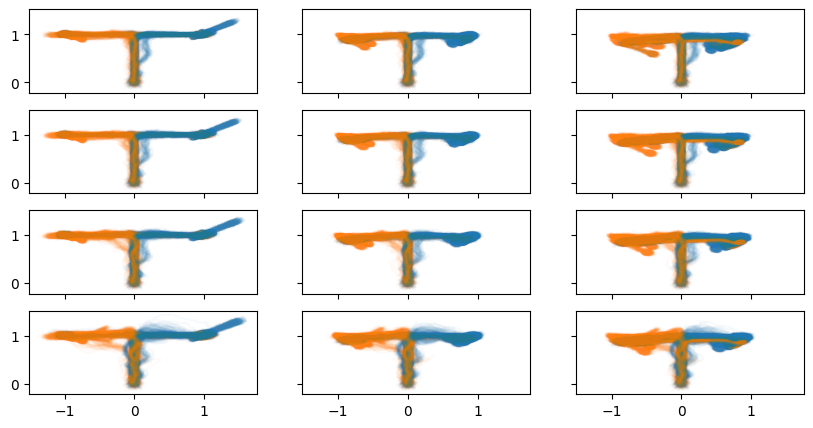

In [4]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:,g,j,:,0], x_hat[:,g,j,:,1], c=f'C{g}', alpha=0.03)

100%|███████████████████████████████████████████| 12/12 [00:16<00:00,  1.37s/it]


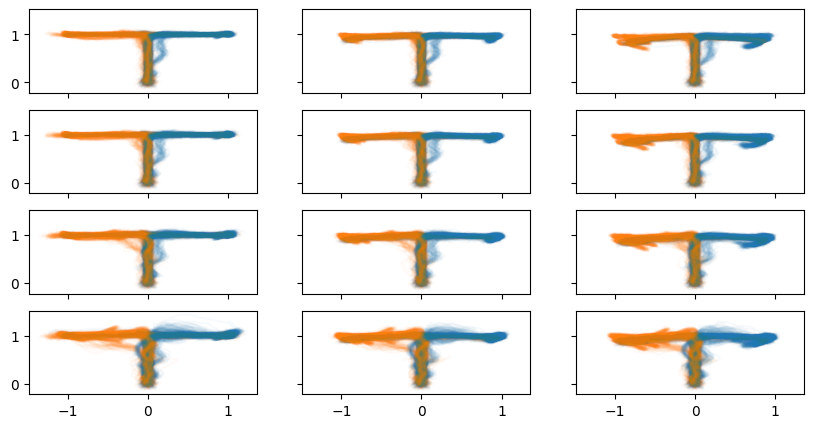

In [5]:
fig, axs = plt.subplots(nrows=4, ncols=3, figsize=(10,5), sharex=True, sharey=True)
axs = axs.flatten()
for i,p in enumerate(tqdm(param_combos)):
    x_hat = replays[str(p)]
    for j in range(len(seeds)):
        for g in range(groups):
            # x_hat has shape (T*T_multiplier, groups, len(seeds), N//groups, 2)
            axs[i].plot(x_hat[:len(awake_trajectories),g,j,:,0],
                        x_hat[:len(awake_trajectories),g,j,:,1], c=f'C{g}', alpha=0.03)

In [6]:
every_region_count_value, region_count_avgs, \
every_distance, distance_avgs = calc_exploration_metrics(dataset, replays, min_duration=20)

df_rcnt_avg = dict_to_csv(region_count_avgs, col_param="b_a",
                          path=f"csv/exploration_{dataset}_region_counts_avg.csv")
df_dist_avg = dict_to_csv(distance_avgs, col_param="b_a",
                          path=f"csv/exploration_{dataset}_distances_avg.csv")

In [7]:
print("Exploration p-values:")
p = {k: ttest_rel(every_region_count_value[str(param_combos[0])].flatten(), v.flatten()).pvalue
     for (k,v) in every_region_count_value.items()}
p

Exploration p-values:


{"{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.0}": nan,
 "{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.01}": 1.8559544980735754e-08,
 "{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.02}": 7.619217822974099e-118,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.0}": nan,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.01}": 7.875235223434555e-10,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.02}": 1.7538485358846888e-104,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.0}": nan,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.01}": 8.019752470905732e-09,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.02}": 8.868581828042726e-95,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.0}": 0.15738570874397217,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.01}": 2.3333443575578005e-06,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.02}": 9.037641117759119e-56}

In [8]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{"{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.0}": 0.15738570874397217}

In [9]:
print("Distance-traveled p values:")
p = {k: ttest_rel(every_distance[str(param_combos[0])].flatten(), v.flatten()).pvalue
     for (k,v) in every_distance.items()}
p

Distance-traveled p values:


{"{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.0}": nan,
 "{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.01}": 1.5815451024728504e-05,
 "{'sigma_r': 0.05, 'lambda_v': 1, 'b_a': 0.02}": 2.322943999932012e-15,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.0}": 0.0001312762353605583,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.01}": 0.16517387268952705,
 "{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.02}": 2.2603642363883086e-20,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.0}": 8.01492486974209e-38,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.01}": 2.0168000124409516e-25,
 "{'sigma_r': 0.05, 'lambda_v': 0.8, 'b_a': 0.02}": 1.9167235497054813e-62,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.0}": 1.4205975774875842e-145,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.01}": 1.2292054151726218e-146,
 "{'sigma_r': 0.05, 'lambda_v': 0.7, 'b_a': 0.02}": 4.730962930590808e-190}

In [10]:
print("p-values above 0.05:")
{k: v for (k,v) in p.items() if v > 0.05}

p-values above 0.05:


{"{'sigma_r': 0.05, 'lambda_v': 0.9, 'b_a': 0.01}": 0.16517387268952705}

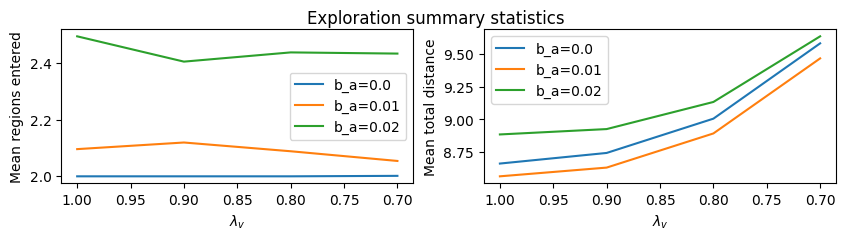

In [11]:
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10,2))
for i, b_a in enumerate([0.0, 0.01, 0.02]):
    x = df_rcnt_avg['lambda_v']
    label = f'{b_a=}'
    axs[0].plot(x, df_rcnt_avg[label], label=label)
    axs[1].plot(x, df_dist_avg[f'{b_a=}'], label=label)
for ax in axs:
    ax.legend()
    ax.xaxis.set_inverted(True)
    ax.set(xlabel='$\lambda_v$')
axs[0].set(ylabel='Mean regions entered')
axs[1].set(ylabel='Mean total distance')
fig.suptitle('Exploration summary statistics')
fig.show()

In [12]:
# flatten replays: combine the len(seeds) and num samples dimensions together.
replays = {k: v.flatten(start_dim=2, end_dim=3) for (k,v) in replays.items()}
# calculate reach time statistics
reach_times, rt_meds, rt_avgs, rt_stds, failure_rates = \
    dict_reach_stats(replays, endpoints, radius)
awake_rts, awake_rt_med, awake_rt_avg, awake_rt_std, _ = \
    reach_stats(awake_trajectories, endpoints, radius)
# reshape medians and avgs for plotting,
# and normalize them in terms of % change from awake statistics
delta_arrays = {
    'median':  (np.array(list(rt_meds.values())).reshape(4,3) / awake_rt_med - 1) * 100,
    'average': (np.array(list(rt_avgs.values())).reshape(4,3) / awake_rt_avg - 1) * 100
}

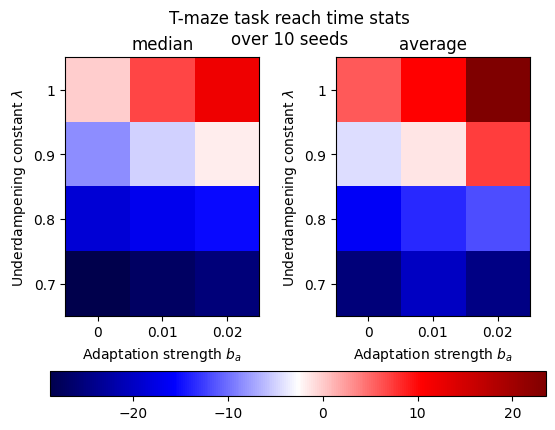

In [13]:
cmap = plt.cm.seismic #c = 'seismic'
fig, axs = plt.subplots(nrows=1, ncols=len(delta_arrays))
vmin = min([a.min() for a in delta_arrays.values()])
vmax = max([a.max() for a in delta_arrays.values()])
for i,(k,v) in enumerate(delta_arrays.items()):
    im = axs[i].imshow(v, cmap=cmap, vmin=vmin, vmax=vmax)
    axs[i].set(title=k,
               xlabel='Adaptation strength $b_a$',
               ylabel='Underdampening constant $\lambda$',
               xticks=[0,1,2], xticklabels=[0,0.01,0.02],
               yticks=[0,1,2,3], yticklabels=[1,0.9,0.8,0.7])
fig.colorbar(im, ax=axs.ravel().tolist(), location='bottom')
fig.suptitle(f'T-maze task reach time stats\nover {len(seeds)} seeds');

In [14]:
# save results
array_to_heatmap(delta_arrays['median'],  f'csv/med_rt_heatmap_{dataset}.txt')
array_to_heatmap(delta_arrays['average'], f'csv/avg_rt_heatmap_{dataset}.txt');

Make sure to add newlines before plotting in TikZ
Make sure to add newlines before plotting in TikZ


In [15]:
wds = calc_all_metric(replays, awake_trajectories, 'wd')
wds = dict_to_csv(wds, col_param='b_a', path=f'csv/wd_{dataset}.csv');

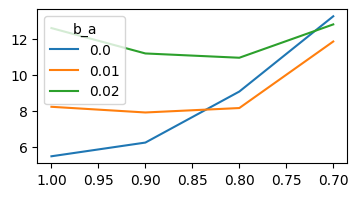

In [16]:
plt.figure(figsize=(4,2))
for b_a in [0.0, 0.01, 0.02]:
    plt.plot(wds['lambda_v'], wds[f'b_a={b_a}'], label=b_a)
plt.legend(title='b_a')
plt.gca().xaxis.set_inverted(True)